Dataset shape: (1000, 21)

Target distribution:
class
good    700
bad     300
Name: count, dtype: int64
=== Logistic Regression ===
ROC-AUC Score: 0.7621 | F1-Score: 0.7410
                 precision    recall  f1-score   support

 Bad Credit (0)       0.47      0.70      0.56        60
Good Credit (1)       0.84      0.66      0.74       140

       accuracy                           0.68       200
      macro avg       0.65      0.68      0.65       200
   weighted avg       0.73      0.68      0.69       200

-------------------------------------------------------
=== Decision Tree ===
ROC-AUC Score: 0.6292 | F1-Score: 0.7160
                 precision    recall  f1-score   support

 Bad Credit (0)       0.42      0.58      0.49        60
Good Credit (1)       0.79      0.66      0.72       140

       accuracy                           0.64       200
      macro avg       0.60      0.62      0.60       200
   weighted avg       0.68      0.64      0.65       200

------------------

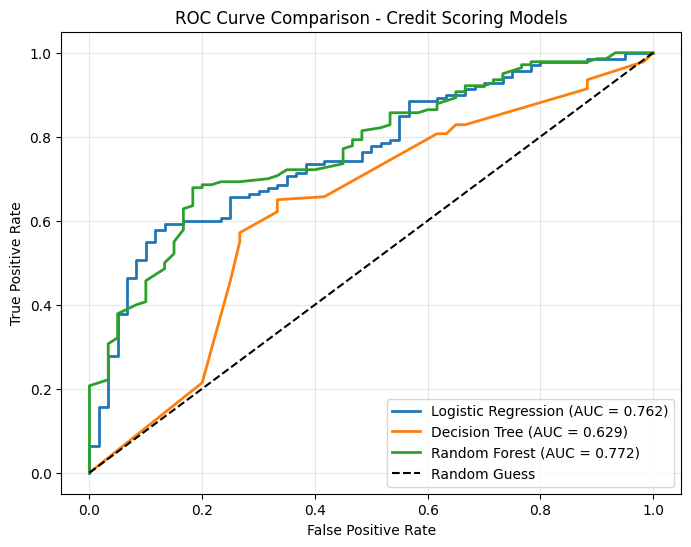

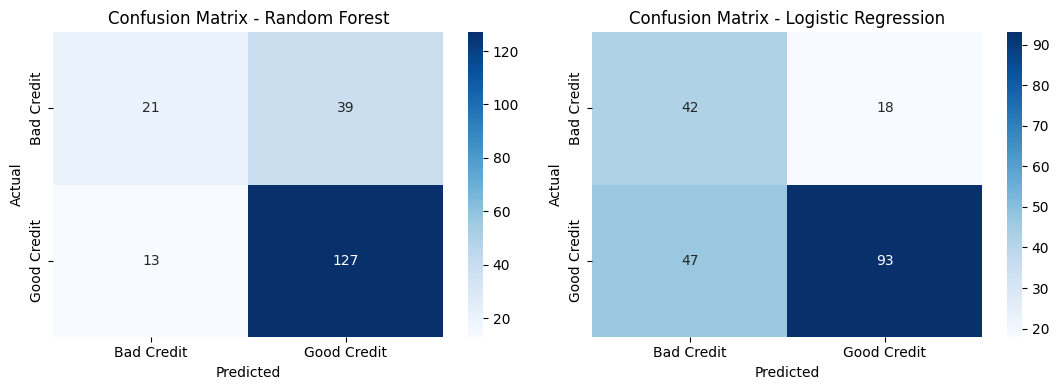


Recall for Bad Credit (class 0):
  Logistic Regression: 0.700
  Decision Tree: 0.583
  Random Forest: 0.350


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    f1_score,
    recall_score
)

credit = fetch_openml('credit-g', version=1, as_frame=True)
df = credit.frame.copy()

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df['class'].value_counts())

df['target'] = (df['class'] == 'good').astype(int)
df = df.drop('class', axis=1)


df['credit_per_month'] = df['credit_amount'] / df['duration']

X = df.drop('target', axis=1)
y = df['target']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['category', 'object']).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
}

results = {}
roc_data = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_prob)
    f1 = f1_score(y_test, y_pred)
    results[name] = {'pipeline': pipe, 'y_pred': y_pred, 'auc': auc, 'f1': f1}

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)

    print(f"=== {name} ===")
    print(f"ROC-AUC Score: {auc:.4f} | F1-Score: {f1:.4f}")
    print(classification_report(y_test, y_pred, target_names=['Bad Credit (0)', 'Good Credit (1)']))
    print("-" * 55)

plt.figure(figsize=(8, 6))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.title("ROC Curve Comparison - Credit Scoring Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ["Random Forest", "Logistic Regression"]):
    cm = confusion_matrix(y_test, results[name]['y_pred'])
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=['Bad Credit', 'Good Credit'],
        yticklabels=['Bad Credit', 'Good Credit']
    )
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

print("\nRecall for Bad Credit (class 0):")
for name, r in results.items():
    rec = recall_score(y_test, r['y_pred'], pos_label=0)
    print(f"  {name}: {rec:.3f}")